<a href="https://colab.research.google.com/github/Ramuna0512/FDS-Lab-Programs/blob/main/250701583_Exp%20No%206.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

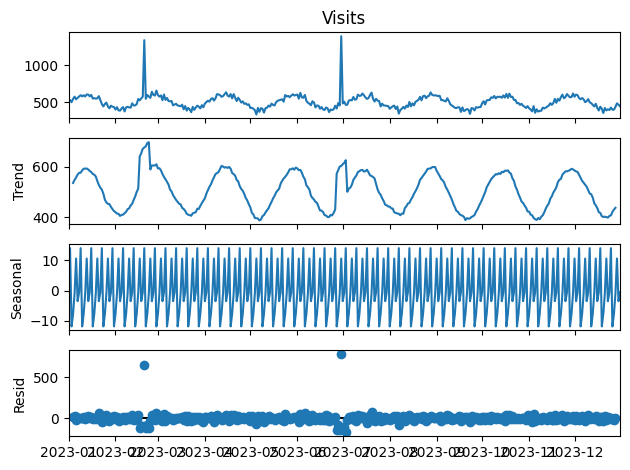

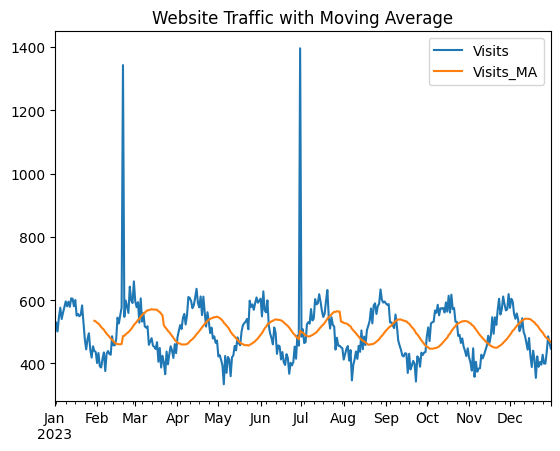

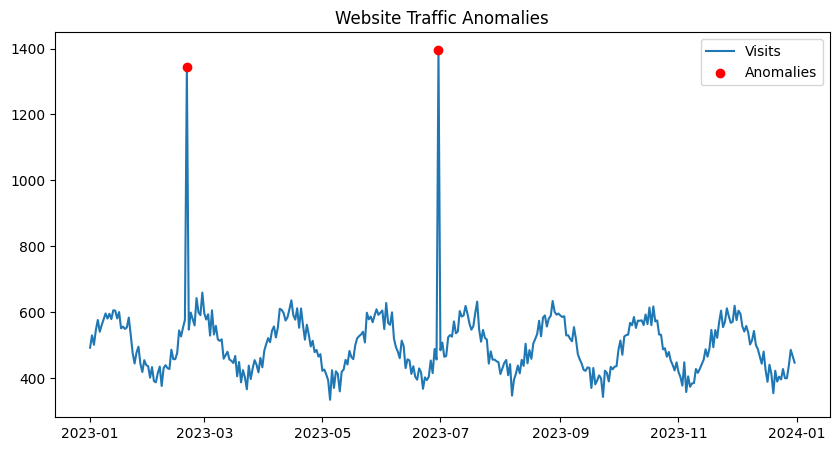

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose

np.random.seed(42)
dates = pd.date_range(start='2023-01-01', periods=365, freq='D')
visits = np.random.poisson(lam=500, size=365) + np.sin(np.linspace(0, 50, 365)) * 100

visits[50] += 800
visits[180] += 950

data = pd.DataFrame({'Visits': visits}, index=dates)

decomposition = seasonal_decompose(data['Visits'], model='additive', period=7)
decomposition.plot()
plt.show()

data['Visits_MA'] = data['Visits'].rolling(window=30).mean()
data[['Visits', 'Visits_MA']].plot()
plt.title('Website Traffic with Moving Average')
plt.show()

data['Visits_Z'] = (data['Visits'] - data['Visits'].mean()) / data['Visits'].std()
anomalies = data[data['Visits_Z'].abs() > 3]

plt.figure(figsize=(10, 5))
plt.plot(data.index, data['Visits'], label='Visits')
plt.scatter(anomalies.index, anomalies['Visits'], color='red', label='Anomalies', zorder = 5)
plt.title('Website Traffic Anomalies')
plt.legend()
